In [1]:
!uv sync --package simpler-mcp

Resolved 205 packages in 3ms
Audited 174 packages in 2ms


# Multimodal MCPs Are Simpler Than You Think

## Let other agents search your data

You have photos and video. Other people have agents. An MCP server gives those agents named tools for searching your catalog.

We will build four recipes. Each recipe adds a kind of search to Pixeltable, proves it in this notebook, then exposes it through MCP. The server can search and answer. It cannot add media, drop tables, or run arbitrary Python.

This tutorial was inspired by Miguel Otero Pedrido's [How real AI Engineers build MCP Servers](https://theneuralmaze.substack.com/p/how-real-ai-engineers-build-mcp-servers), Alex Razvant's [Building MCP Servers for Video Search Engines](https://read.theaimerge.com/p/building-mcp-servers-for-video-search), and Avi Chawla's [Build the Ultimate MCP Server for Multimodal AI](https://blog.dailydoseofds.com/p/build-the-ultimate-mcp-server-for/).

In [2]:
import atexit
import os
from pathlib import Path
import socket
import subprocess
import time

import mcp
from mcp.client.streamable_http import streamablehttp_client
import pixeltable as pxt

MCP_URL = 'http://127.0.0.1:8000/mcp'
server_process = None


def restart_server():
    """Restart FastMCP so its tool list matches the current schema."""
    global server_process
    if server_process is not None:
        server_process.terminate()
        server_process.wait(timeout=10)
    server_process = subprocess.Popen(
        ['uv', 'run', '--package', 'simpler-mcp', 'python', 'server.py'],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.STDOUT,
    )
    for _ in range(60):
        if server_process.poll() is not None:
            raise RuntimeError('The MCP server stopped during startup.')
        try:
            with socket.create_connection(('127.0.0.1', 8000), timeout=1):
                return
        except OSError:
            time.sleep(1)
    raise TimeoutError('The MCP server did not start within 60 seconds.')


async def list_mcp_tools():
    async with streamablehttp_client(MCP_URL) as (read, write, _):
        async with mcp.ClientSession(read, write) as session:
            await session.initialize()
            return [tool.name for tool in (await session.list_tools()).tools]


async def call_mcp_tool(name, arguments):
    async with streamablehttp_client(MCP_URL) as (read, write, _):
        async with mcp.ClientSession(read, write) as session:
            await session.initialize()
            return await session.call_tool(name, arguments)


@atexit.register
def stop_server():
    if server_process is not None:
        server_process.terminate()


# Uncomment this once when you want a clean catalog, then run from Recipe 1.
# pxt.drop_dir('mcp_demo', force=True)

## Recipe 1: search titles and captions

Start with the words on each photo. Human titles are short. BLIP adds a caption as a computed column.

Run the search in Pixeltable first. Then start the MCP and call the same search as a tool.

"""Recipe 1: search photo titles and generated captions.

Apply it with:
    pxt schema diff recipe1_store.py mcp_demo
    pxt schema update recipe1_store.py mcp_demo
"""

import pixeltable as pxt
import pixeltable.functions as pxtf

TableModel = pxt.model_base()


class Photos(TableModel, name='photos'):
    """Photos that people can search through the MCP."""

    photo_id: pxt.Required[pxt.Int]
    image: pxt.Required[pxt.Image]
    title: pxt.String | None

    search_title = title.lower()
    caption = pxtf.huggingface.image_captioning(
        image,
        model_id='Salesforce/blip-image-captioning-base',
        model_kwargs={'max_length': 30},
    )


class Queries(TableModel, name='queries'):
    """Questions and images sent to the MCP search tools."""

    query_id: pxt.Required[pxt.String]
    tool: pxt.Required[pxt.String]
    text: pxt.String | None
    image: pxt.Image | None
    created_at: pxt.Required[pxt.Timestamp]



+ mcp_demo/photos          create
+ mcp_demo/queries         create

Plan: 2 create, 0 update, 0 unchanged, 0 extra  |  0 destructive


created   mcp_demo/photos
created   mcp_demo/queries


Connected to Pixeltable database at: postgresql+psycopg://postgres:@/pixeltable?host=/var/folders/zz/d4wytf2s44996j3sr4zgthw80000gn/T/4c657d322e


/Users/alison-pxt/Documents/Github/pixeltable-youtube/.venv/lib/python3.14/site-packages/pixeltable/env.py:367: UserWarning: Progress reporting is disabled because ipywidgets is not installed. To fix this, run: `pip install ipywidgets`
  warnings.warn(


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 473/473 [00:00<00:00, 50535.07it/s]

Inserted 6 rows with 0 errors in 6.77 s (0.89 rows/s)


photo_id,image,title,caption
3,,Zebra grazing,a zebra grazing in a field
5,,Zebra in an enclosure,a zebra standing next to a fence

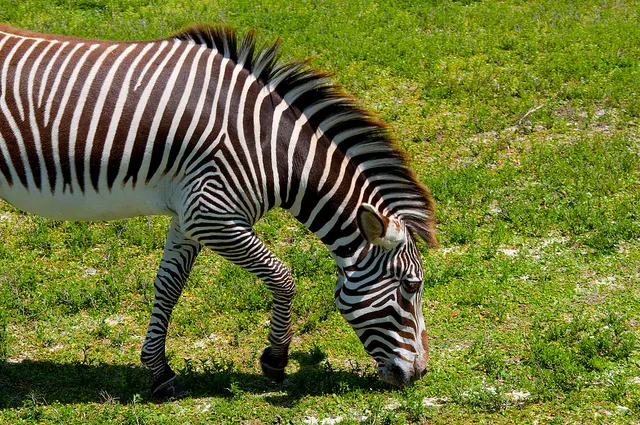
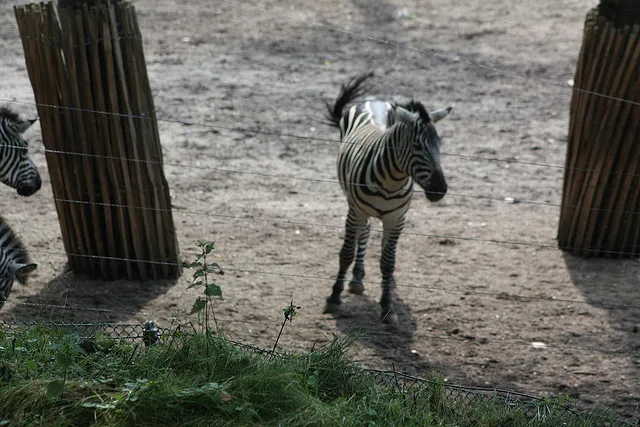

In [3]:
print(Path('recipe1_store.py').read_text())
!pxt schema diff recipe1_store.py mcp_demo
!pxt schema update recipe1_store.py mcp_demo -f

BASE = 'https://raw.githubusercontent.com/pixeltable/pixeltable/main/docs/resources/images/'
photos = pxt.get_table('mcp_demo.photos')
if photos.count() == 0:
    photos.insert([
        {'photo_id': 1, 'image': BASE + '000000000001.jpg', 'title': 'Taxi on a city street'},
        {'photo_id': 2, 'image': BASE + '000000000025.jpg', 'title': 'Giraffe at the zoo'},
        {'photo_id': 3, 'image': BASE + '000000000034.jpg', 'title': 'Zebra grazing'},
        {'photo_id': 4, 'image': BASE + '000000000061.jpg', 'title': 'Elephant trek in the jungle'},
        {'photo_id': 5, 'image': BASE + '000000000080.jpg', 'title': 'Zebra in an enclosure'},
        {'photo_id': 6, 'image': BASE + '000000000090.jpg', 'title': 'Cow in a pasture'},
    ])

# Pixeltable search
photos.where(photos.search_title.contains('zebra')).select(
    photos.photo_id, photos.image, photos.title, photos.caption
).collect()

In [4]:
# Caption search still needs the same word.
photos.where(photos.caption.lower().contains('striped')).select(
    photos.photo_id, photos.image, photos.title, photos.caption
).collect()

# MCP search
restart_server()
await list_mcp_tools(), await call_mcp_tool(
    'search_photo_text', {'query': 'zebra', 'limit': 5}
)

(['search_photo_text'],
 CallToolResult(meta=None, content=[TextContent(type='text', text='[{"photo_id": 3, "title": "Zebra grazing", "caption": "a zebra grazing in a field"}, {"photo_id": 5, "title": "Zebra in an enclosure", "caption": "a zebra standing next to a fence"}]', annotations=None, meta=None)], structuredContent={'result': '[{"photo_id": 3, "title": "Zebra grazing", "caption": "a zebra grazing in a field"}, {"photo_id": 5, "title": "Zebra in an enclosure", "caption": "a zebra standing next to a fence"}]'}, isError=False))

## Recipe 2: search image content

Words miss a photo when the title and caption use different language. CLIP compares the question with the pixels.

Apply the index, run the search in Pixeltable, then restart the server. The new MCP tool appears because the index now exists.

In [5]:
print(Path('recipe2_search.py').read_text())
!pxt schema diff recipe2_search.py mcp_demo
!pxt schema update recipe2_search.py mcp_demo -f

photos = pxt.get_table('mcp_demo.photos')
score = photos.image.similarity(string='a striped animal', idx='clip_idx')
photos.order_by(score, asc=False).select(
    photos.photo_id, photos.image, photos.title, score=score
).limit(3).collect()

restart_server()
await list_mcp_tools(), await call_mcp_tool(
    'search_photo_content', {'query': 'a striped animal', 'limit': 5}
)

"""Recipe 2: search image content with CLIP.

Apply it with:
    pxt schema diff recipe2_search.py mcp_demo
    pxt schema update recipe2_search.py mcp_demo
"""

import pixeltable as pxt
import pixeltable.functions as pxtf

TableModel = pxt.model_base()


class Photos(TableModel, name='photos'):
    """Photos with text search and image similarity search."""

    photo_id: pxt.Required[pxt.Int]
    image: pxt.Required[pxt.Image]
    title: pxt.String | None

    search_title = title.lower()
    caption = pxtf.huggingface.image_captioning(
        image,
        model_id='Salesforce/blip-image-captioning-base',
        model_kwargs={'max_length': 30},
    )

    __indexes__ = [
        pxt.EmbeddingIndex(
            image,
            embedding=pxtf.huggingface.clip.using(model_id='openai/clip-vit-base-patch32'),
            name='clip_idx',
        )
    ]


class Queries(TableModel, name='queries'):
    """Questions and images sent to the MCP search tools."""

    query_id: pxt.Requir

~ mcp_demo/photos          update
    + EmbeddingIndex 'clip_idx' will be added  safe
= mcp_demo/queries         no change

Plan: 0 create, 1 update, 1 unchanged, 0 extra  |  0 destructive


updated   mcp_demo/photos
unchanged mcp_demo/queries


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 38840.67it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 59137.49it/s]

(['search_photo_text', 'search_photo_content'],
 CallToolResult(meta=None, content=[TextContent(type='text', text='[{"photo_id": 3, "title": "Zebra grazing", "caption": "a zebra grazing in a field", "score": 0.3417098759}, {"photo_id": 5, "title": "Zebra in an enclosure", "caption": "a zebra standing next to a fence", "score": 0.3254917904}, {"photo_id": 2, "title": "Giraffe at the zoo", "caption": "a gife standing on a rock", "score": 0.252324465}, {"photo_id": 6, "title": "Cow in a pasture", "caption": "a cow grazing in a field", "score": 0.2257787518}, {"photo_id": 1, "title": "Taxi on a city street", "caption": "a truck is parked in front of a fence", "score": 0.2200475192}]', annotations=None, meta=None)], structuredContent={'result': '[{"photo_id": 3, "title": "Zebra grazing", "caption": "a zebra grazing in a field", "score": 0.3417098759}, {"photo_id": 5, "title": "Zebra in an enclosure", "caption": "a zebra standing next to a fence", "score": 0.3254917904}, {"photo_id": 2, "tit

## Recipe 3: search video

A video search starts with frames. Pixeltable samples each video, captions the frames, and keeps a CLIP index on them.

Search the frames in Pixeltable first. The MCP then adds two ways to get a short clip. One starts with text. The other starts with an image.

"""Recipe 3: search video frames and return short clips.

Apply it with:
    pxt schema diff recipe3_video.py mcp_demo
    pxt schema update recipe3_video.py mcp_demo
"""

import pixeltable as pxt
import pixeltable.functions as pxtf

TableModel = pxt.model_base()


class Photos(TableModel, name='photos'):
    """Photos with text search and image similarity search."""

    photo_id: pxt.Required[pxt.Int]
    image: pxt.Required[pxt.Image]
    title: pxt.String | None

    search_title = title.lower()
    caption = pxtf.huggingface.image_captioning(
        image,
        model_id='Salesforce/blip-image-captioning-base',
        model_kwargs={'max_length': 30},
    )

    __indexes__ = [
        pxt.EmbeddingIndex(
            image,
            embedding=pxtf.huggingface.clip.using(model_id='openai/clip-vit-base-patch32'),
            name='clip_idx',
        )
    ]


class Queries(TableModel, name='queries'):
    """Questions and images sent to the MCP search tools."""

    query_id: 

= mcp_demo/photos          no change
= mcp_demo/queries         no change
+ mcp_demo/videos          create
+ mcp_demo/video_frames    create

Plan: 2 create, 0 update, 2 unchanged, 0 extra  |  0 destructive


unchanged mcp_demo/photos
unchanged mcp_demo/queries
created   mcp_demo/videos
created   mcp_demo/video_frames


Inserted 26 rows with 0 errors in 10.38 s (2.50 rows/s)


video_id,title,frame,caption,clip,time_seconds,score
1,"Lex Fridman Podcast 430, excerpt 0",,a man in a suit and tie sitting at a desk,,5.,0.253
1,"Lex Fridman Podcast 430, excerpt 0",,a man in a suit sitting at a table with a microphone,,50.,0.251
1,"Lex Fridman Podcast 430, excerpt 0",,a man in a suit and tie sitting at a desk,,10.,0.251

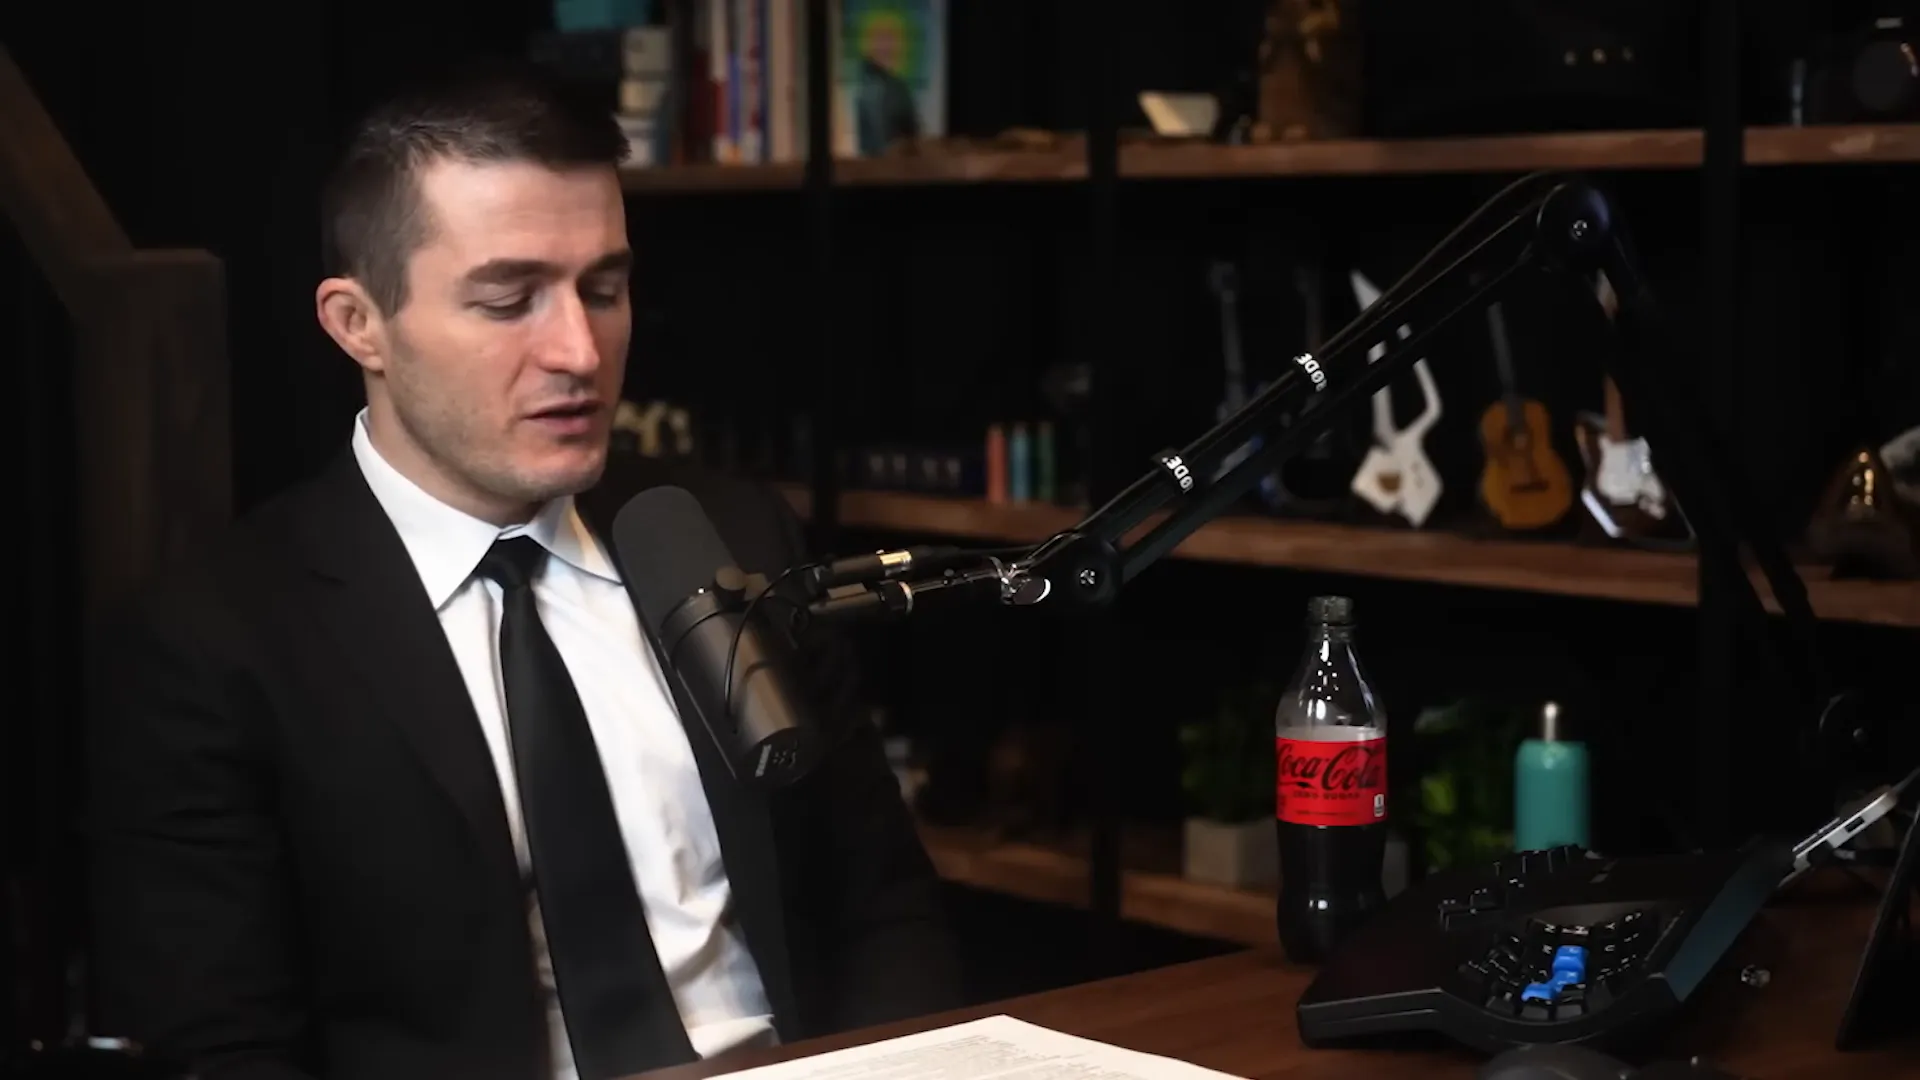
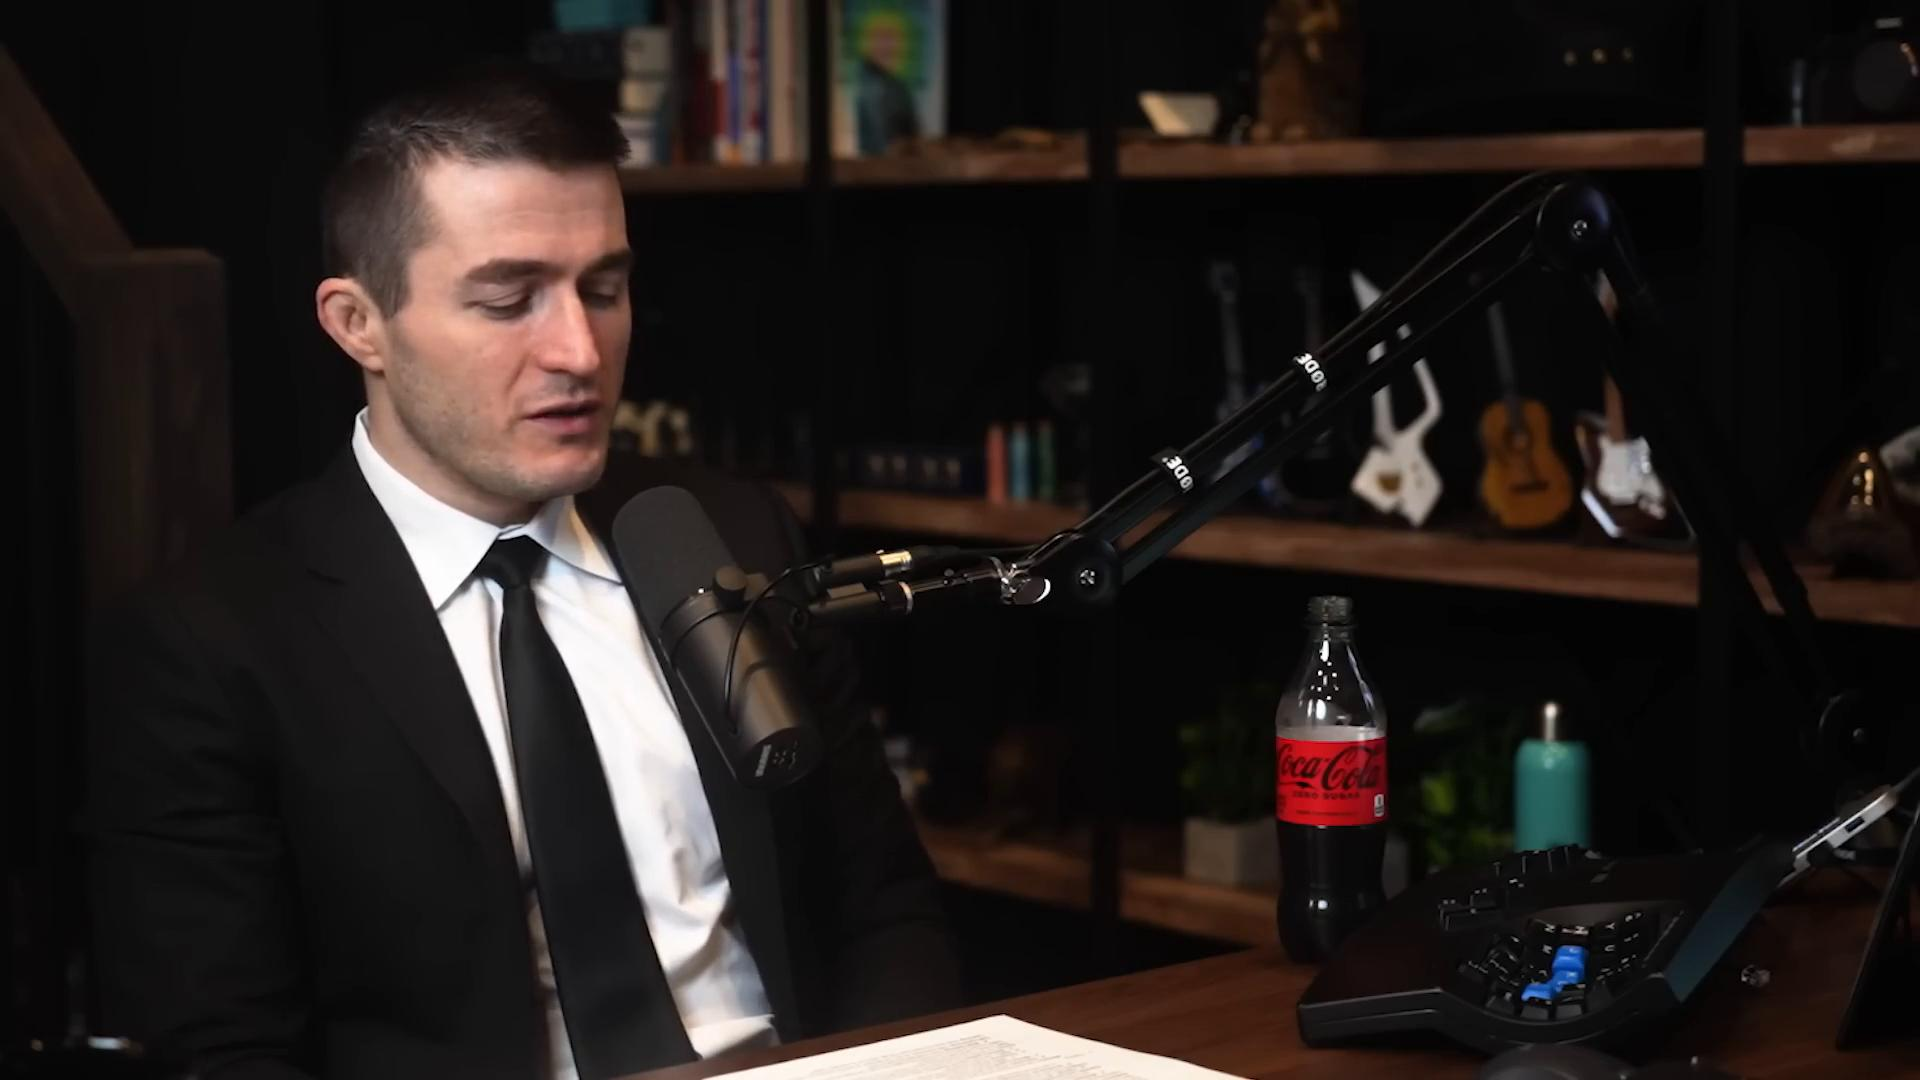
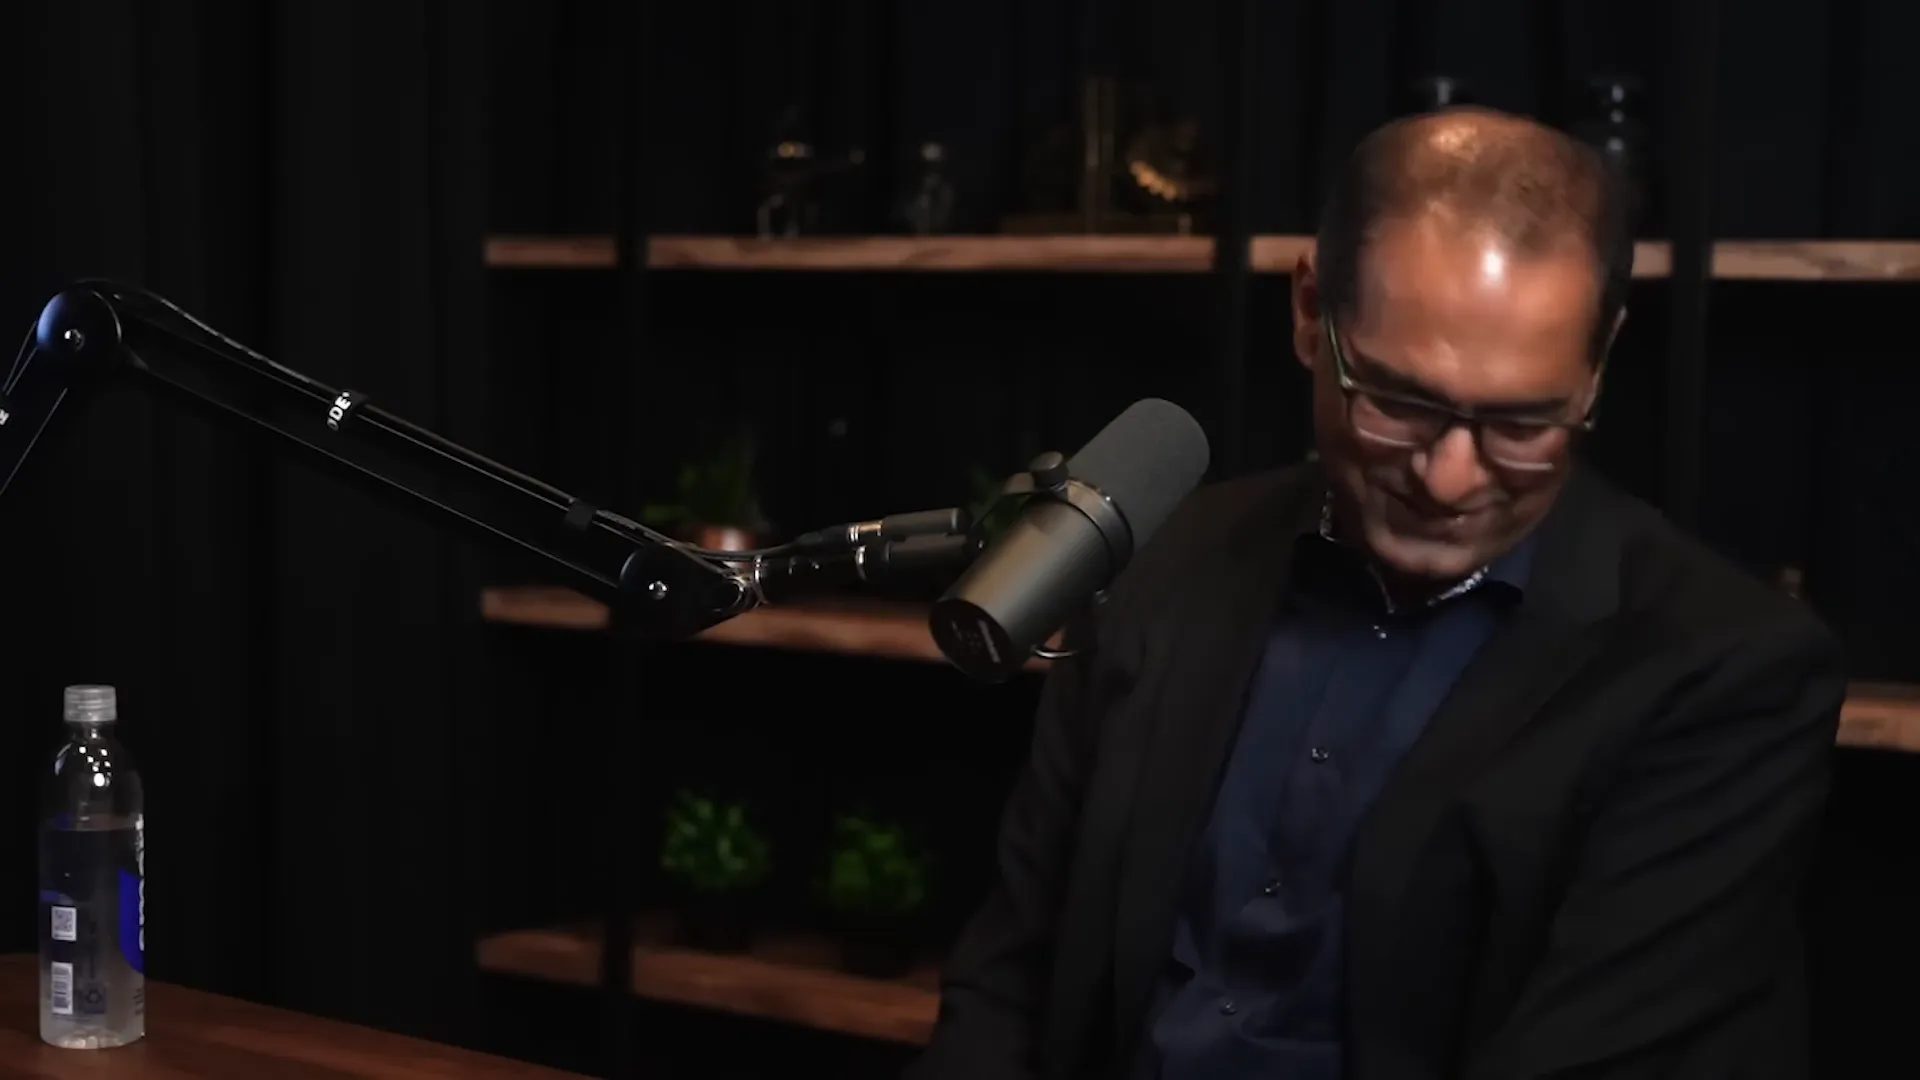
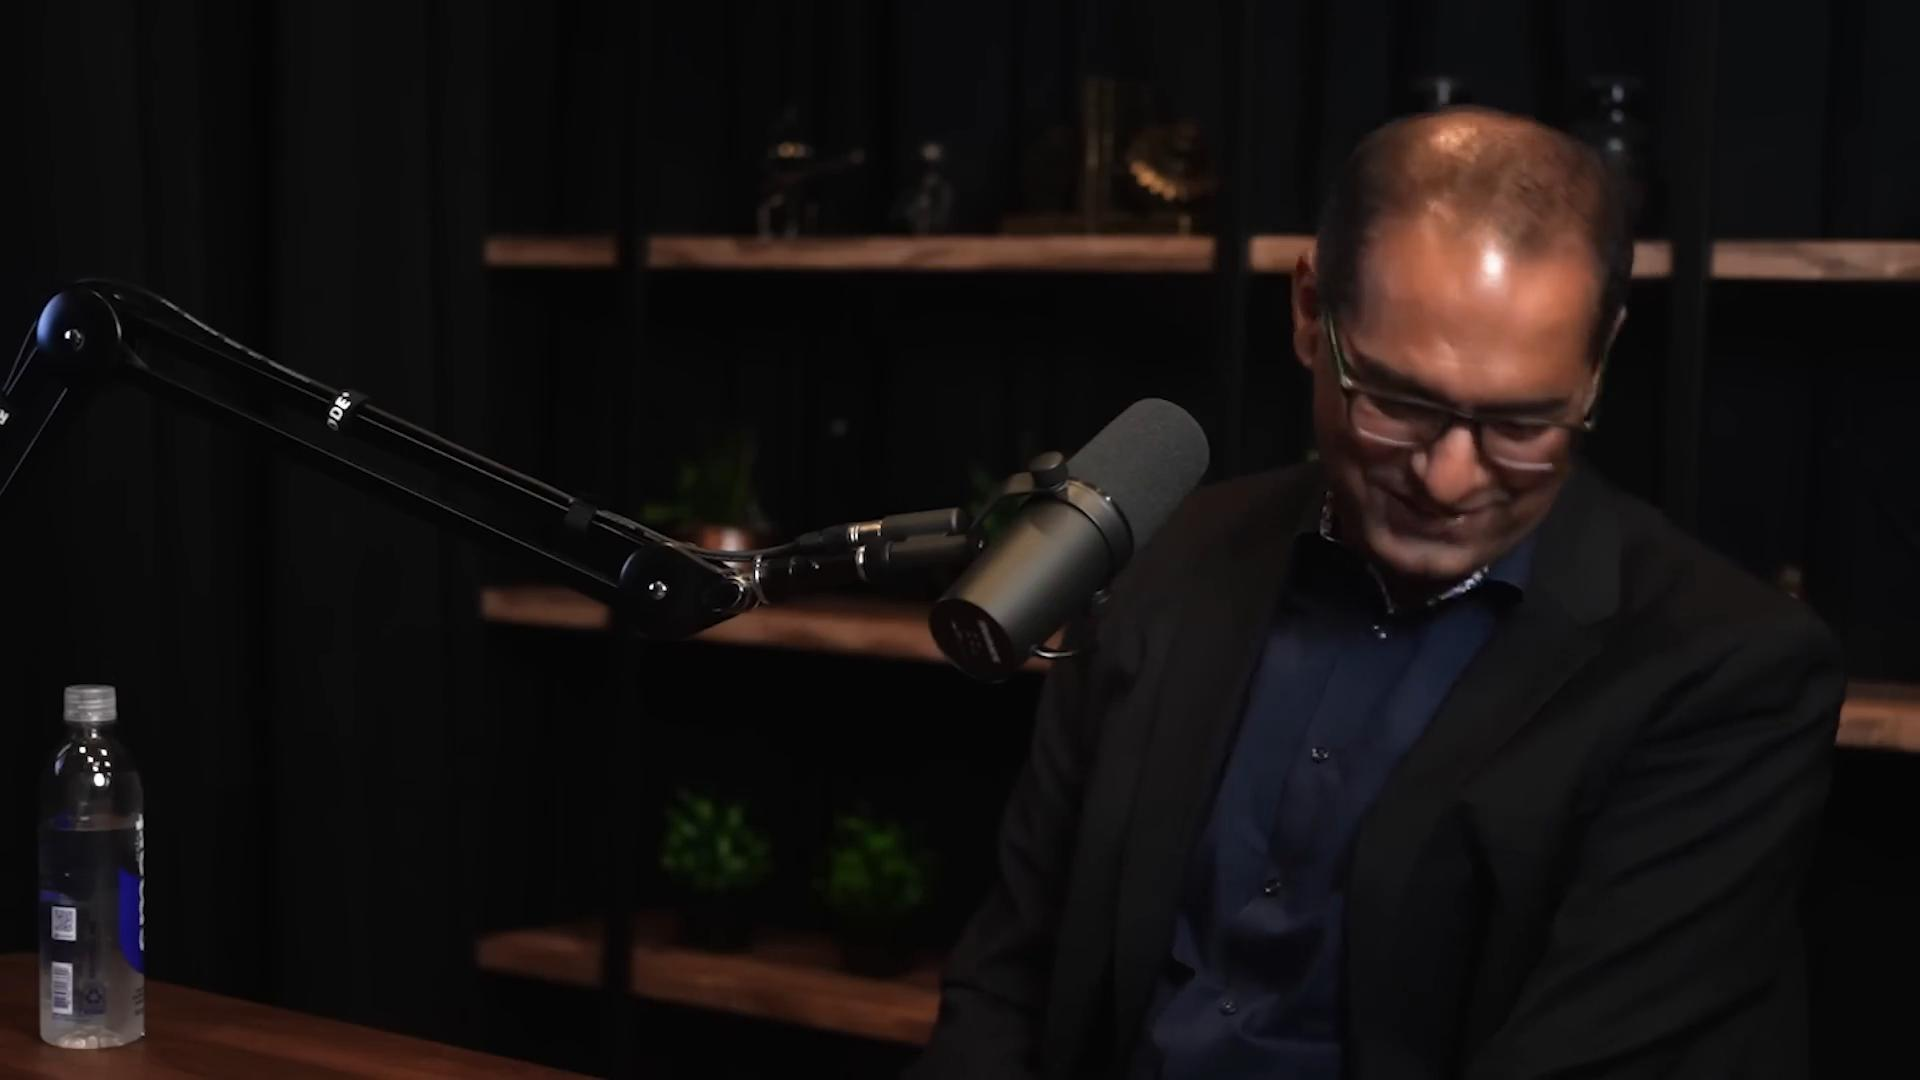
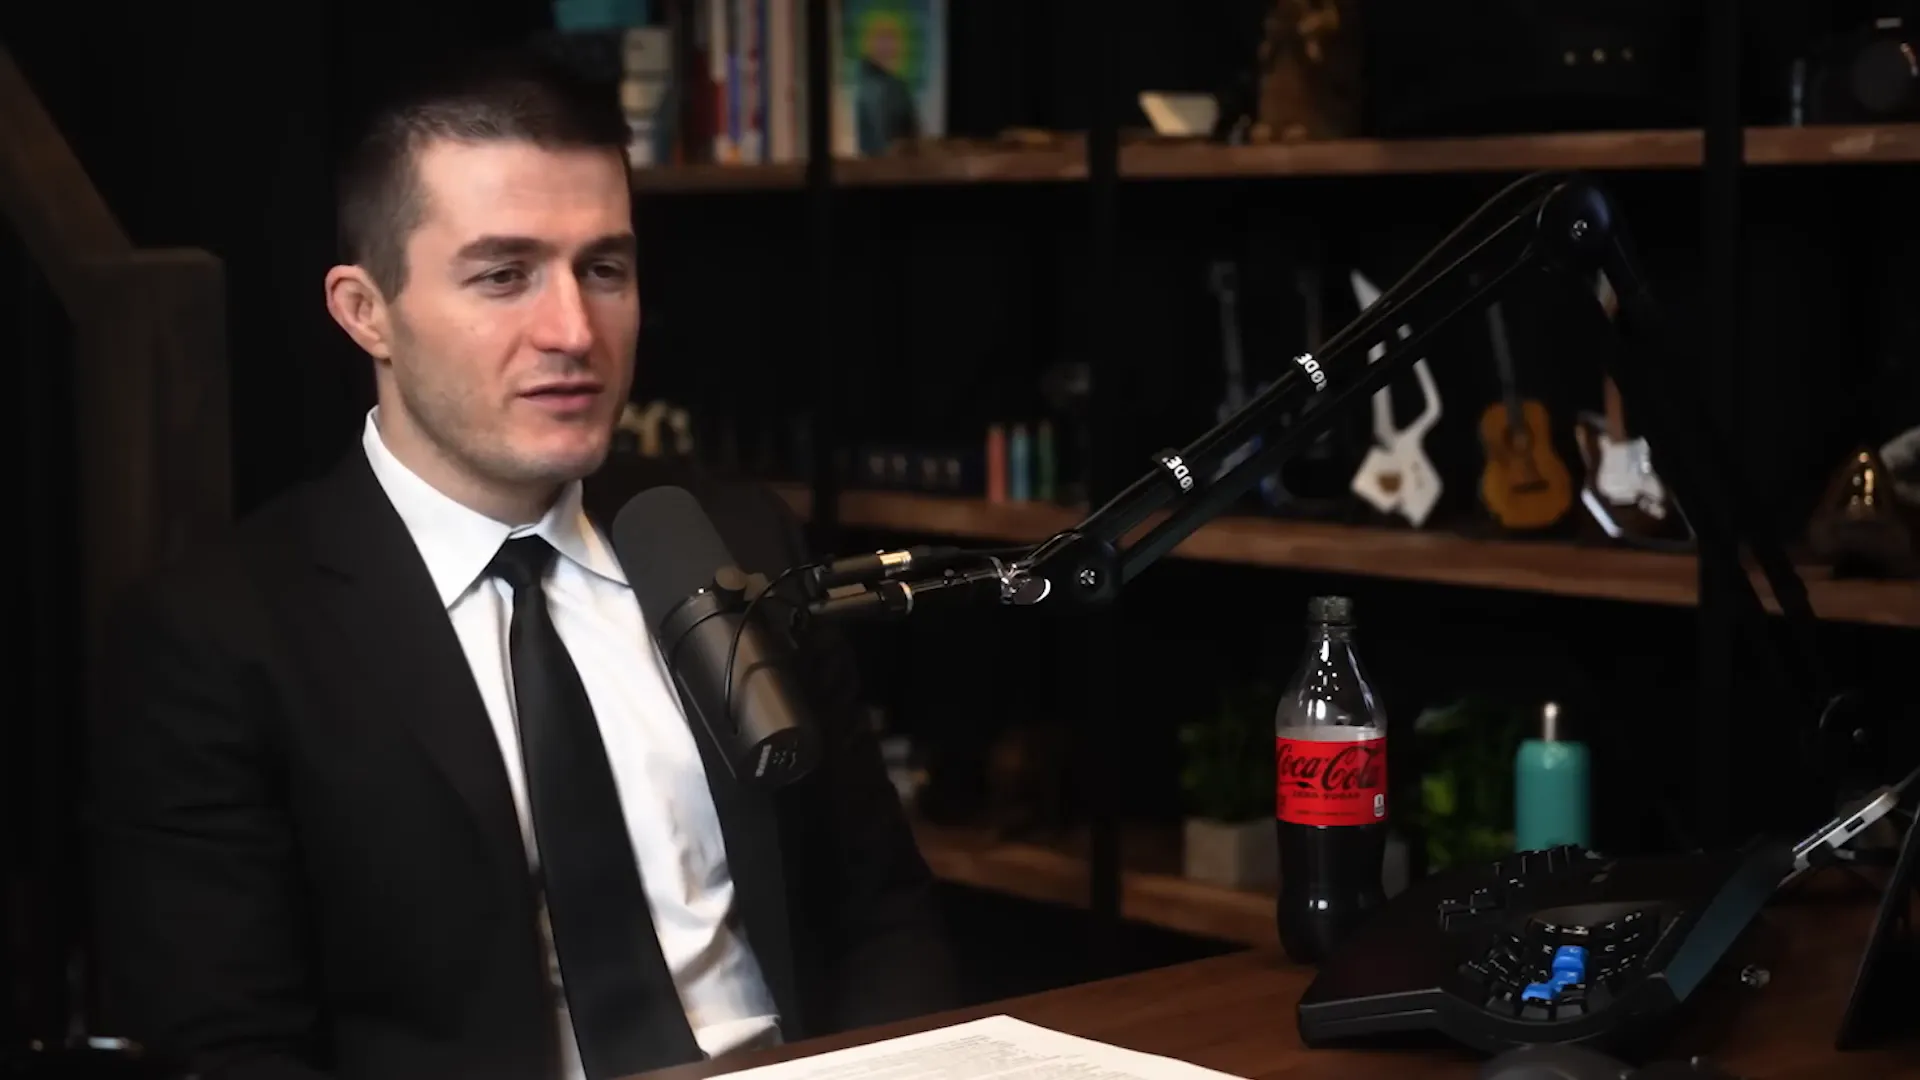
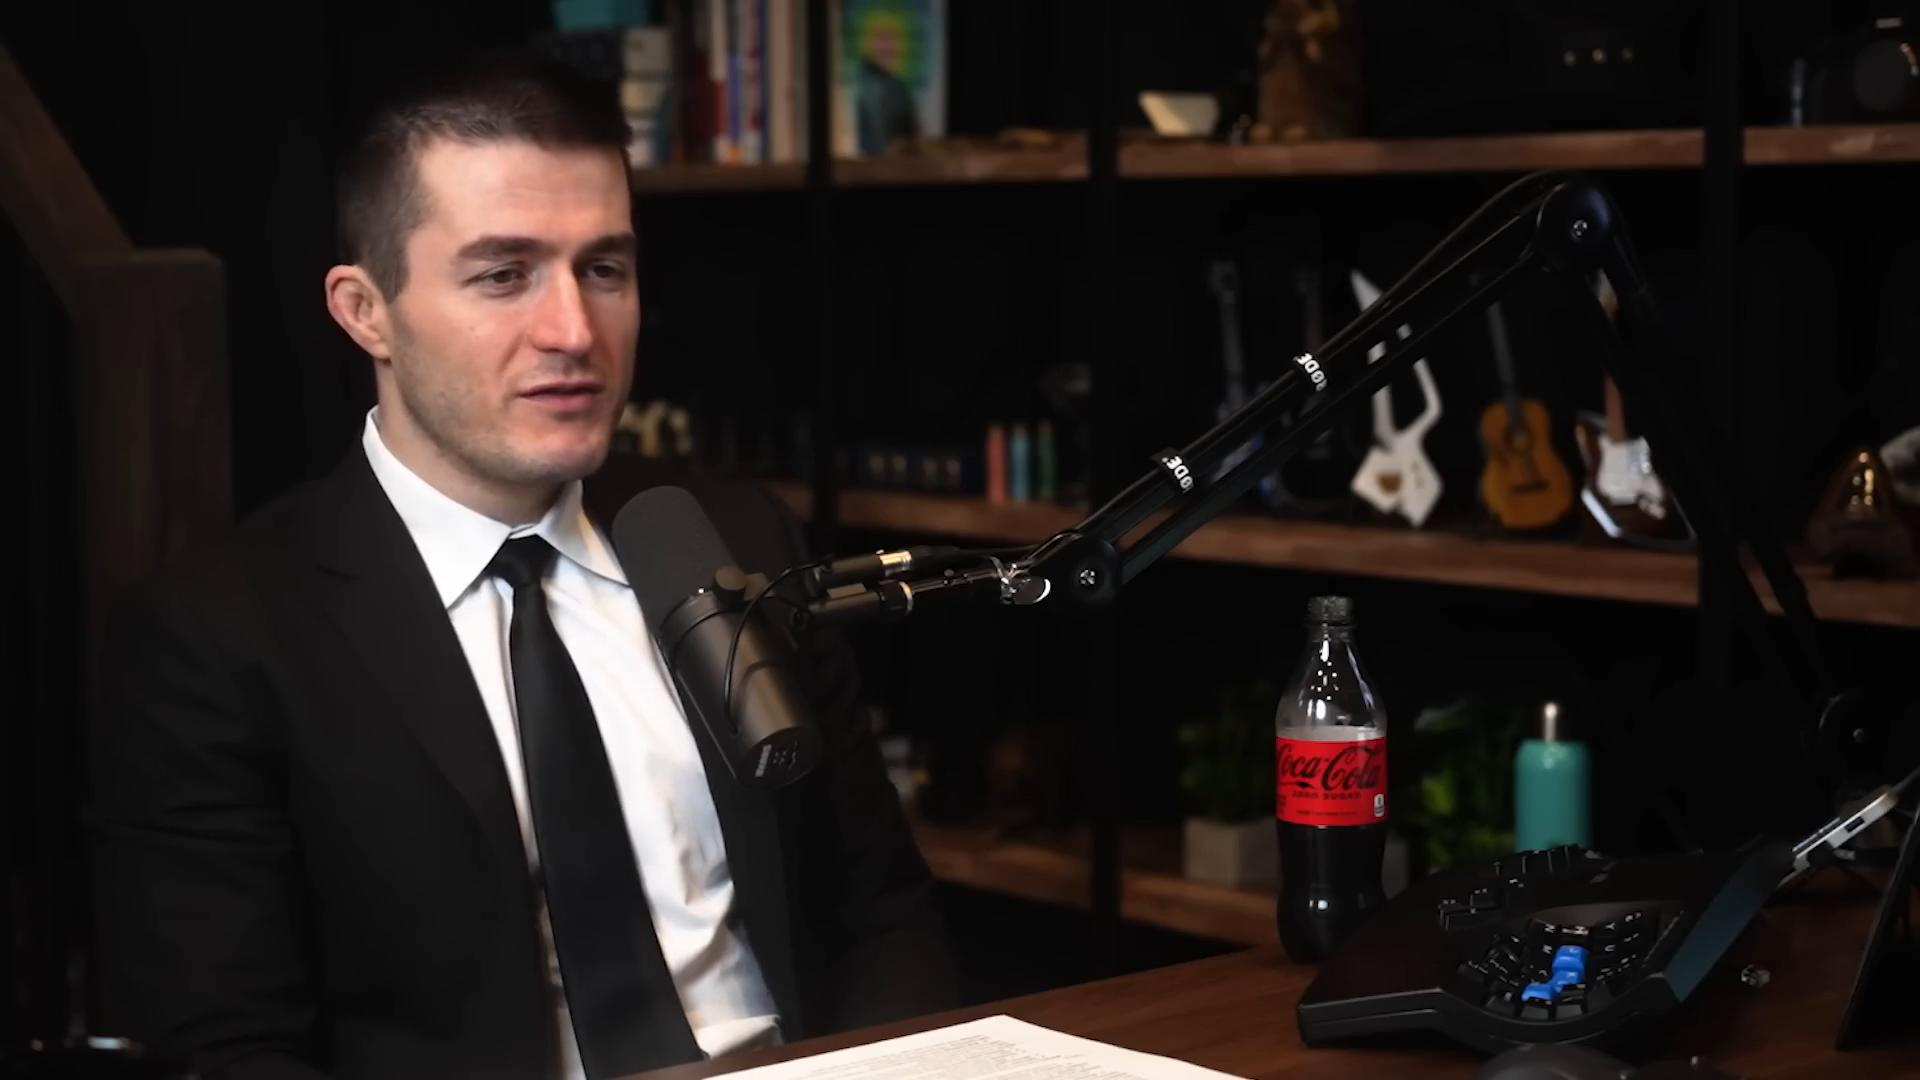

In [6]:
print(Path('recipe3_video.py').read_text())
!pxt schema diff recipe3_video.py mcp_demo
!pxt schema update recipe3_video.py mcp_demo -f

VIDEO_BASE = (
    'https://github.com/pixeltable/pixeltable/raw/release/'
    'docs/resources/audio-transcription-demo/'
)
videos = pxt.get_table('mcp_demo.videos')
if videos.count() == 0:
    videos.insert([
        {
            'video_id': 1,
            'video': VIDEO_BASE + 'Lex-Fridman-Podcast-430-Excerpt-0.mp4',
            'title': 'Lex Fridman Podcast 430, excerpt 0',
        },
        {
            'video_id': 2,
            'video': VIDEO_BASE + 'Lex-Fridman-Podcast-430-Excerpt-1.mp4',
            'title': 'Lex Fridman Podcast 430, excerpt 1',
        },
    ])

frames = pxt.get_table('mcp_demo.video_frames')
scene_score = frames.frame.similarity(string='two people talking in a studio', idx='frame_clip_idx')
frames.order_by(scene_score, asc=False).select(
    frames.video_id,
    frames.title,
    frames.frame,
    frames.caption,
    frames.clip,
    time_seconds=frames.frame_attrs.time,
    score=scene_score,
).limit(3).collect()

In [7]:
restart_server()
text_clip = await call_mcp_tool(
    'get_clip_for_text', {'query': 'two people talking in a studio'}
)
text_clip

# Save one stored frame, then send its path as the image query.
query_frame = frames.select(frames.frame).limit(1).collect().to_pandas().iloc[0]['frame']
query_frame_path = Path('/tmp/mcp-query-frame.jpg')
query_frame.save(query_frame_path)
image_clip = await call_mcp_tool(
    'get_clip_for_image', {'image': str(query_frame_path)}
)
image_clip

CallToolResult(meta=None, content=[TextContent(type='text', text='{"video_id": 1, "title": "Lex Fridman Podcast 430, excerpt 0", "time_seconds": 0.0, "caption": "a man in a suit and tie sitting at a desk", "score": 0.9969537556718364}', annotations=None, meta=None), EmbeddedResource(type='resource', resource=BlobResourceContents(uri=AnyUrl('file:///Users/alison-pxt/Documents/Github/pixeltable-youtube/simpler-mcp/.pixeltable/verify4/media/99c2c11046da4e6b863363601bd27590/16/1621/99c2c11046da4e6b863363601bd27590_4_1_162124ebbdc749289db64bec29f4aff4.mp4'), mimeType='video/mp4', meta=None, blob='...'), annotations=None, meta=None)], structuredContent={'result': [{'type': 'text', 'text': '{"video_id": 1, "title": "Lex Fridman Podcast 430, excerpt 0", "time_seconds": 0.0, "caption": "a man in a suit and tie sitting at a desk", "score": 0.9969537556718364}', 'annotations': None, '_meta': None}, {'type': 'resource', 'resource': {'uri': 'file:///Users/alison-pxt/Documents/Github/pixeltable-yout

## Recipe 4: answer from captions and transcripts

Frames tell you what was on screen. Audio tells you what people said. Pixeltable extracts the audio and runs a local Whisper model.

Search captions and transcripts in Pixeltable. The final MCP tool retrieves from both indexes, then stores and returns an answer. It needs `OPENAI_API_KEY` for the answer column.

In [8]:
print(Path('recipe4_transcript.py').read_text())
!pxt schema diff recipe4_transcript.py mcp_demo
!pxt schema update recipe4_transcript.py mcp_demo -f

videos = pxt.get_table('mcp_demo.videos')
frames = pxt.get_table('mcp_demo.video_frames')
question = 'What do they say about intelligence?'

speech_score = videos.transcript.similarity(string=question, idx='transcript_idx')
videos.order_by(speech_score, asc=False).select(
    videos.video_id, videos.title, videos.transcript, score=speech_score
).limit(2).collect()

"""Recipe 4: search video captions and transcripts, then answer a question.

Apply it with:
    pxt schema diff recipe4_transcript.py mcp_demo
    pxt schema update recipe4_transcript.py mcp_demo
"""

import pixeltable as pxt
import pixeltable.functions as pxtf

TableModel = pxt.model_base()

TEXT_EMBEDDING = pxtf.huggingface.sentence_transformer.using(
    model_id='sentence-transformers/all-MiniLM-L6-v2'
)


class Photos(TableModel, name='photos'):
    """Photos with text search and image similarity search."""

    photo_id: pxt.Required[pxt.Int]
    image: pxt.Required[pxt.Image]
    title: pxt.String | None

    search_title = title.lower()
    caption = pxtf.huggingface.image_captioning(
        image,
        model_id='Salesforce/blip-image-captioning-base',
        model_kwargs={'max_length': 30},
    )

    __indexes__ = [
        pxt.EmbeddingIndex(
            image,
            embedding=pxtf.huggingface.clip.using(model_id='openai/clip-vit-base-patch32'),
            name='

= mcp_demo/photos          no change
= mcp_demo/queries         no change
~ mcp_demo/videos          update
    + column 'audio' will be added  safe
    + column 'transcript' will be added  safe
    + column 'transcription' will be added  safe
    + EmbeddingIndex 'transcript_idx' will be added  safe
~ mcp_demo/video_frames    update
    + EmbeddingIndex 'caption_idx' will be added  safe
+ mcp_demo/answers         create

Plan: 1 create, 2 update, 2 unchanged, 0 extra  |  0 destructive


unchanged mcp_demo/photos
unchanged mcp_demo/queries
updated   mcp_demo/videos
updated   mcp_demo/video_frames
created   mcp_demo/answers


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 24109.23it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 18328.17it/s]

video_id,title,transcript,score
2,"Lex Fridman Podcast 430, excerpt 1","or worse, the young adults at episodic memory. And I always say, would say, God, this is so weird. Why would we have this period of time that's so short when we're perfect, right? We're optimal. And I like to use that word optimal now because there's such a culture of optimization right now. And it's like, I realized I have to redefine what optimal is because for most of the human condition, I think we had a series of stages of life where you have basically adults saying, okay, young adults saying, I've got a child and I'm part of this village and I have to hunt and forage and get things done. I need a prefrontal cortex so I can stay focused on the big picture and long haul goals. Now I'm a child. I'm in this village and kind of wandering around and I've got some safety and I need to learn about this culture because I know so little. What's the best way to do that? Let's explore. I don't want to be constrained by goals as much. I want to really be free.",0.171
1,"Lex Fridman Podcast 430, excerpt 0","of experiencing self versus remembering self. I was hoping you can give a simple answer of how we should live life. Based on the fact that our memories could be a source of happiness, or could be the primary source of happiness, that an event when experienced bears its fruits the most, when it's remembered over and over and over and over. Maybe there is some wisdom in the fact that we can control to some degree how we remember it, how we evolve our memory of it, such that it can maximize the long-term happiness of that repeated experience. Okay, well first I'll say, I wish I could take you on the road with me. That was such a great description. Can I be your opening excerpt? Oh my god, no I'm going to open for you dude. Otherwise it's like, everybody leaves after you've done.",0.068


In [9]:
restart_server()
if os.getenv('OPENAI_API_KEY'):
    answer = await call_mcp_tool(
        'ask_about_video', {'question': question, 'limit': 3}
    )
    answer
else:
    print('Set OPENAI_API_KEY where the Pixeltable daemon runs, then rerun this cell.')

# The data owner can inspect every MCP search and every stored answer.
queries = pxt.get_table('mcp_demo.queries')
answers = pxt.get_table('mcp_demo.answers')
queries.order_by(queries.created_at, asc=False).select(
    queries.tool, queries.text, queries.image, queries.created_at
).limit(10).collect(), answers.select(
    answers.question, answers.source_notes, answers.answer, answers.created_at
).collect()

(                   tool                                  text  \
 0       ask_about_video  What do they say about intelligence?   
 1    get_clip_for_image                                   NaN   
 2     get_clip_for_text        two people talking in a studio   
 3  search_photo_content                      a striped animal   
 4     search_photo_text                                 zebra   
 
                                                image  \
 0                                               None   
 1  <PIL.JpegImagePlugin.JpegImageFile image mode=...   
 2                                               None   
 3                                               None   
 4                                               None   
 
                         created_at  
 0 2026-09-01 18:20:11.145287-06:00  
 1 2026-09-01 18:19:46.106905-06:00  
 2 2026-09-01 18:19:43.748283-06:00  
 3 2026-09-01 18:19:23.844168-06:00  
 4 2026-09-01 18:19:09.054968-06:00  ,
                             

## Keep the data boundary

The final MCP can search photos, return video clips, and answer from captions and transcripts. It also stores tool calls in `queries` for the data owner.

The server has no tool for adding media or dropping tables. Those operations stay with the data owner.

In [10]:
# The final tool list contains no drop or media-ingest tool.
await list_mcp_tools()

stop_server()